# Check PSO Results

## Run and plot top 10 scoring parameters from PSO

In [1]:
import os
import sys
sys.path.insert(0, "./cellular_cycle") # add path to the model
sys.path.insert(0, "./fit") # add path to the fit functions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import sobol_seq
from pathlib import Path

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from Austin_proliferation_model_concentration_6 import model
model_concentration=model
from Austin_proliferation_model_population_6 import model
model_population=model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator

# Directory containing cell fate data
DATADIR = Path('../Data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
# SAVE_DIR = 'D:\\stoch_runs_230713\\'
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files


### Model parameters
Models should be identical whether running as ODE or stochastic. The only difference is how the observables are tracked (as concentrations or numbers of molecules). Setting omega to 1 in the concentration model should produce the same output as the population model



In [2]:
# Confirming the new model parameters are included in the model
omega = 200
new_param = pd.read_csv(Path("../Matlab/v2/parameters.csv"))
del new_param['Stress']
del new_param['K_sp21']
for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = new_param[key]
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]

model_concentration.parameters['omega'].value = 1   # this should make the a concentration output match the molecular count output


In [3]:
model_population.parameters['ERK'].value = 1 * omega
model_population.parameters['FAK'].value = 1 * omega
model_population.parameters['AKT'].value = 1 * omega

model_concentration.parameters['ERK'].value = 1 * 1
model_concentration.parameters['FAK'].value = 1 * 1
model_concentration.parameters['AKT'].value = 1 * 1

## ODE simulation

In [4]:
#ODE simulation
# original     
# t = np.linspace(0, 500, 50000) 
t = np.linspace(0, 1000, 100001) # use for both determininstic and stochstic simulations
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); #deterministic simulation
yout = simres.all;
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A


#### Define a function for producing a plot showing the time-dependence of the observable species in the model

In [5]:
def plotObs(model, obs, times, tpos, title=None, ax=None, legend=True, **kwargs):
    """Plot an observable of a model"""
    if ax is None:
        ax = plt.gca()
    # plt.plot(tspan,model[obs][tspan], label=obs, lw=2)

    for o in obs:
        ax.plot(times[tpos], model[o][tpos], label=o)
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Concentration')
    if title is not None:
        ax.set_title(title)
    if legend:
        ax.legend(loc="upper right")
    return ax


<Axes: xlabel='Time (h)', ylabel='Concentration'>

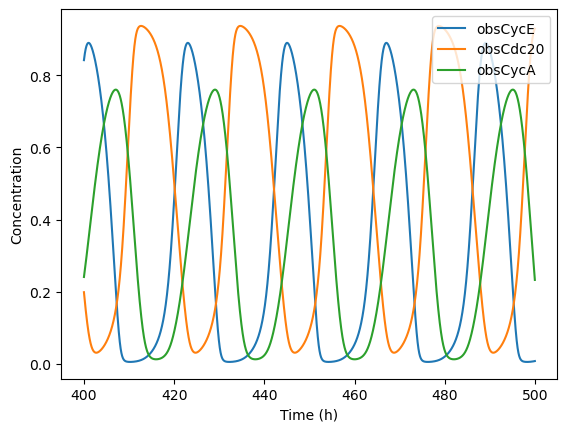

In [6]:
plotObs(model=yout, obs=observables, times=t, tpos=range(40000,50000), legend=True)

### Import PSO params

In [7]:
all_params = pd.read_csv("./fit_data_parameters_pso_simulations_results.csv") 

In [8]:
all_params_cost = all_params.sort_values('cost.19')
param_names = all_params.iloc[0,56:92].values
top_costs = pd.DataFrame(data=all_params_cost.iloc[0:12,56:92].values, columns=param_names)

### Unclear why the parameter values below are different
Different conditions for ODE vs stochastic sims?  

Using low stiffness condition to look for more obvious differences among PSO-determined optimal parameter sets.

In [9]:
model_population.parameters['ERK'].value = 0.2 * omega
model_population.parameters['FAK'].value = 0.4 * omega
model_population.parameters['AKT'].value = 0.3 * omega

model_concentration.parameters['ERK'].value = 1.0 * 1 ###
model_concentration.parameters['FAK'].value = 0.4 * 1
model_concentration.parameters['AKT'].value = 0.6 * 1 ###

In [10]:
top_costs

,F_n,K_2E2F,K_CD,K_CE,K_DF,K_M,K_MY,K_S,K_p21fak,V_2E2F,...,k_RE,kasbaxmbcl2,kasbh3bcl2,kb,kdbh3,kdsbaxmbcl2,kdsbh3bcl2,kf1,kf2,v_s1p21
0,8.660157835133548,0.5621395275169132,0.5644458575249667,0.6380709428831556,0.9991830587539061,0.22235492626175005,0.11823659609669243,0.6149582357110128,5.731422835762793,0.7937957280409894,...,162.53488570722288,82.13468414735736,24.864078636023876,0.1610733741591959,0.030792602362104262,0.05661659506016427,0.009771592591933219,0.011329662336560662,2.434621453198629,0.6945858160211398
1,7.484264000493251,0.4874005303930365,0.6330748490577153,0.5394079277294466,0.9860238751696768,0.25822347827596287,0.09681274700096958,0.7394522629354493,4.810025523172703,0.7901944227103054,...,204.4849442203738,71.62215507648065,22.67169336385831,0.12892960367392625,0.03145046842601271,0.05339378684454702,0.013798459825059086,0.010852025887513887,2.2405725390073017,0.8017204599226264
2,8.660156335115666,0.5621394364610044,0.5644459217943505,0.6380707954547283,0.9991831849167221,0.22235495352956944,0.11823665537017898,0.6149583163289795,5.731421464391362,0.7937967498257777,...,162.53488880713456,82.1345666304622,24.864079276792754,0.16107335427403022,0.03079260821042765,0.05661659577246148,0.009771594092659945,0.0113296589873959,2.43462145245451,0.6945856557855021
3,7.369678964022715,0.4793095951076391,0.773632848663459,0.5344403447046063,0.9297296881086289,0.2444706732516184,0.10676309093673228,0.6993294458036725,4.901569537770841,0.8231158180131617,...,196.05567913616667,70.5236869544312,23.874776314468548,0.13805928878905935,0.029047834250766423,0.05754978893182192,0.01403534876881012,0.010756286391772512,2.451009593138619,0.7237924768485695
4,7.539330110290429,0.4892069979522081,0.6353802492815231,0.5395603320256815,0.9922653908188352,0.2584099537614839,0.09624426787004352,0.7268275168031549,4.858334759509059,0.7823021056447834,...,203.23428922723488,71.7669288814961,22.632806083197917,0.13116464699591326,0.032268716415661244,0.05407093063338088,0.013895174544256959,0.011015067898279237,2.2023290662969415,0.8049195971147562
5,7.27757519551836,0.47886659546814253,0.6467268457231851,0.5384346804304365,1.0026249768257907,0.26145513534702164,0.09747606047404811,0.7337532618975534,4.820909737372855,0.7943491925268447,...,200.861603388743,71.53554099386974,21.939366922240275,0.12955867338293364,0.03221138918694597,0.054688533748522034,0.014866963705222265,0.010633028359371393,2.231065995972585,0.8108823279536864
6,7.423290175471561,0.47921379005322245,0.6521094636975624,0.5154193876409188,1.017883101969731,0.2537210914650608,0.09317342174962277,0.7204248698719605,4.711768342596577,0.7617339946492802,...,195.11364274944594,69.579085927622,21.720905376527863,0.12970095886271274,0.03031447898133754,0.05466903025204324,0.015326702409327934,0.011445885091466037,2.243375888527698,0.7386354485151422
7,7.635013476659012,0.4947249022710766,0.6393828135981348,0.5398744408050848,1.01249048415486,0.2587512510039746,0.09476126767073996,0.7083669614242559,4.938644302400701,0.7634366745922987,...,201.10934265300168,71.98653196281265,22.555760687604387,0.1355895449524613,0.03331955310106319,0.055283395710350375,0.014132309782314133,0.011360742640837416,2.123481746590981,0.8090190885114591
8,7.395134421232209,0.5341860674176129,0.6395054690724278,0.5183016761625777,0.849651456959004,0.2073494436424903,0.09294560043982306,0.9308677026976887,4.759369226169339,0.8586497147381486,...,167.7964336833731,77.48114456099017,26.589267607429253,0.13512731162290967,0.03294175404794413,0.05139967611501416,0.010900390974238382,0.010982245483518428,2.2700087256291677,0.6198209821593568
9,7.404119735602079,0.48212543986202017,0.6416157143917036,0.5125816659990416,1.013699597406507,0.2535540885178903,0.09333709554059418,0.7626916973030394,4.810435677124986,0.7566127003063472,...,193.08208158049638,72.26871889225548,22.45296874949094,0.13316393214124575,0.03045814741596905,0.05531817136460191,0.015003663825766324,0.011691781832271158,2.35423953

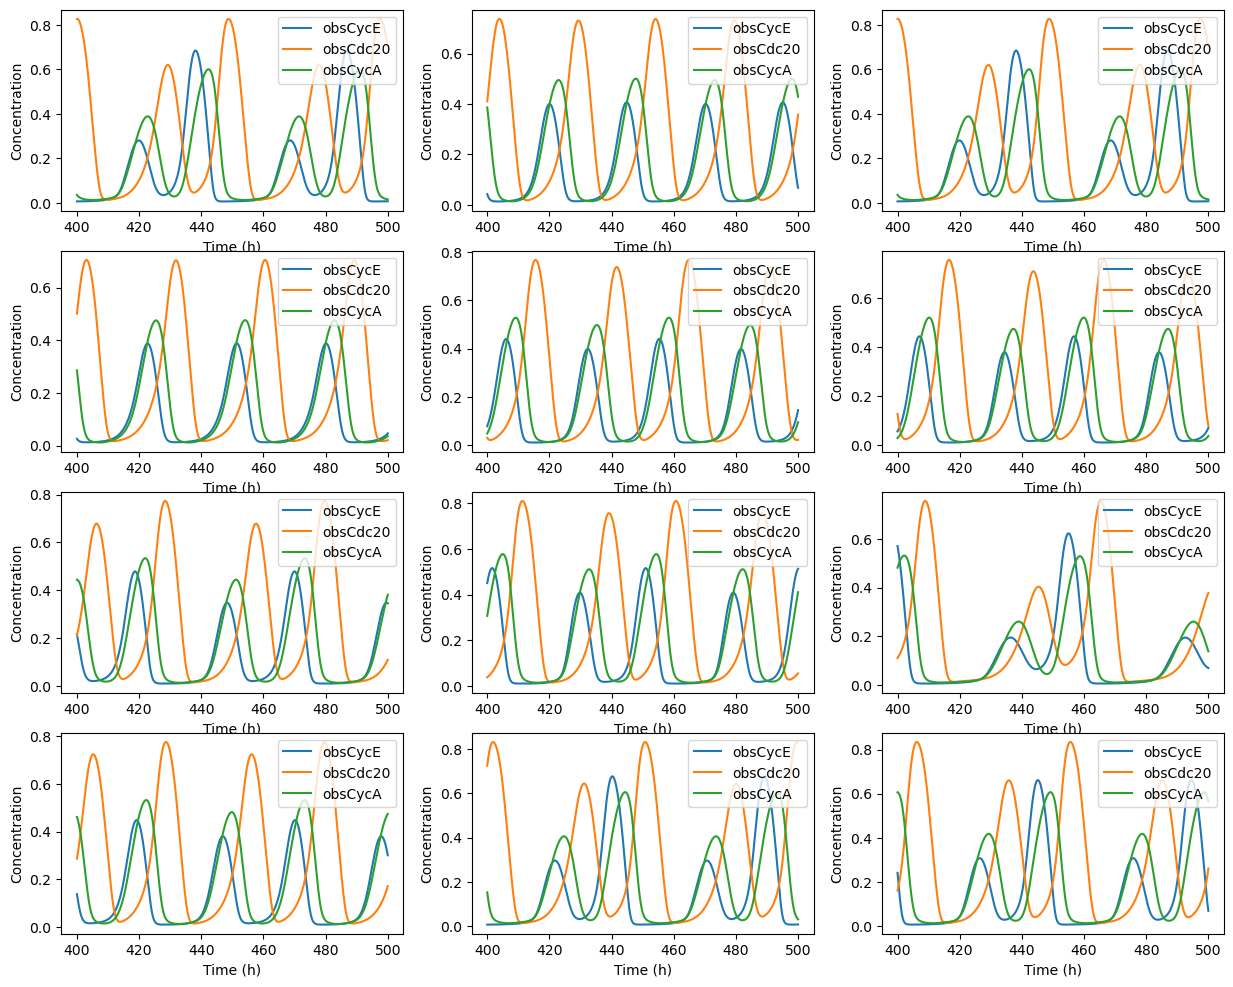

In [11]:
plt.figure(figsize=(15,12))

for num in range(len(top_costs)):
    for name in param_names:
        model_concentration.parameters[name].value = top_costs[name][num]

    simresults = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); # deterministic simulation
    yout2 = simresults.all;
    
    ax = plt.subplot(4, 3, num+1)
    plotObs(model=yout2, obs=observables, times=t, tpos=range(40000,50000), legend=True)



### Run stochastic model

In [12]:
ecm_conditions = pd.read_csv('ECM_conditions.csv', index_col=[0])
ecm_conditions

,stiffness,drug,species,value
condition,,,,
stiff_DMSO,stiff,DMSO,AKT,1.0
stiff_DMSO,stiff,DMSO,ERK,1.0
stiff_DMSO,stiff,DMSO,FAK,1.0
int_DMSO,intermediate,DMSO,AKT,1.0
int_DMSO,intermediate,DMSO,ERK,1.0
int_DMSO,intermediate,DMSO,FAK,0.6
soft_DMSO,soft,DMSO,AKT,0.6
soft_DMSO,soft,DMSO,ERK,1.0
soft_DMSO,soft,DMSO,FAK,0.4


In [13]:
conditions = [
    {
        'AKT': 0.6,
        'ERK': 1,
        'FAK': 0.4
    },
    {
        'AKT': 1,
        'ERK': 1,
        'FAK': 0.6
    },
    {
        'AKT': 1,
        'ERK': 1,
        'FAK': 1
    },
    {
        'AKT': 0.3,
        'ERK': 0.2,
        'FAK': 0.4
    },
    {
        'AKT': 0.6,
        'ERK': 0.2,
        'FAK': 0.6
    },
    {
        'AKT': 0.6,
        'ERK': 0.2,
        'FAK': 1
    }
]

In [14]:
for num in range(2):
    for condition in conditions:
        for name in param_names:
            model_concentration.parameters[name].value = top_costs[name][num]

        model_population.parameters['ERK'].value = condition['ERK'] * omega
        model_population.parameters['FAK'].value = condition['FAK'] * omega
        model_population.parameters['AKT'].value = condition['AKT'] * omega
        
        sim = BngSimulator(model_population, tspan=t, verbose=False); # stochastic simulator
        simres = sim.run(method='ssa', verbose=False, seed=33); # running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
        yout = simres.observables;
        
        AKT = round(condition['AKT']*100)
        ERK = round(condition['ERK']*100)
        FAK = round(condition['FAK']*100)
        
        filename = Path(SAVE_DIR, f'AKT_{AKT}_ERK_{ERK}_FAK_{FAK}_stoch.csv')
        if OVERWRITE or not os.path.exists(filename):
            np.savetxt(filename, yout, delimiter=',')
        
        

### Calc UMAP and plot

In [15]:
import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob

In [16]:
file_location = os.path.join(SAVE_DIR, '*param0.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# print(filenames)

In [17]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 5                    # window size in hours
time_step = 1               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

#reducer save name
r_name = f'reducer_07_13_{init_dt}_{dt}_{window}_{time_step}.sav'

In [18]:
def load_norm_data(filenames, times, init_dt, dt, window, time_step):
    time_tmp2 = pd.DataFrame(data=times)
    time_tmp2.columns = ["time"]
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
    
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp[prot_tmp<0] = 0
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames:
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,18))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
        prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
    return all_prot_tmp, all_time_tmp, all_time_at_tmp
        

In [19]:
def load_norm_data_new(filenames, filenames_ode, time_all, init_dt, dt, window, time_step, plot_phase):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
    
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp

In [20]:
t_loc = '../umap_window/t_4-9_3_3.txt'
# t_loc = 'C:\\Users\\olesk\\repos\\ECM_cell_cycle_model\\umap_window\\t_4-9_3_3.txt'

all_prot_tmp, all_time_tmp, all_time_at_tmp = load_norm_data(filenames, t, init_dt, dt, window, time_step)

In [21]:
len(all_prot_tmp)

59976

In [22]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True
        ).fit(all_prot_tmp)

embedding_all_prot = reducer.transform(all_prot_tmp)

In [23]:
trk_len = int(len(all_prot_tmp)/6)

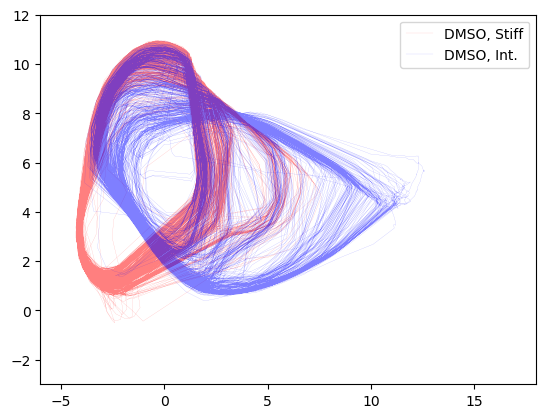

In [24]:
fig = plt.figure()
plt.plot(embedding_all_prot[0*trk_len:1*trk_len,0], embedding_all_prot[0*trk_len:1*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Stiff', color='red')
plt.plot(embedding_all_prot[1*trk_len:2*trk_len,0], embedding_all_prot[1*trk_len:2*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Int.', color='blue')
plt.xlim(-6, 18)
plt.ylim(-3, 12)
plt.legend()

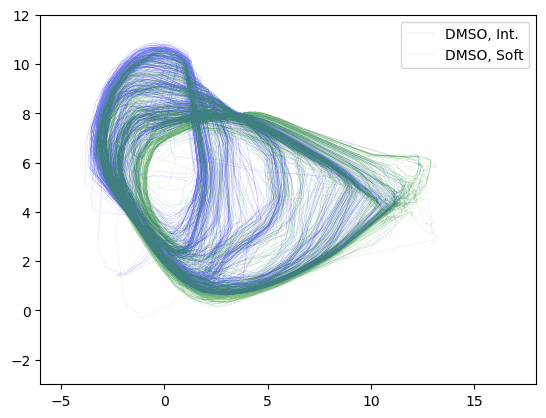

In [25]:
fig = plt.figure()
plt.plot(embedding_all_prot[1*trk_len:2*trk_len,0], embedding_all_prot[1*trk_len:2*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Int.', color='blue')
plt.plot(embedding_all_prot[3*trk_len:4*trk_len,0], embedding_all_prot[3*trk_len:4*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Soft', color='green')
plt.xlim(-6, 18)
plt.ylim(-3, 12)
plt.legend()

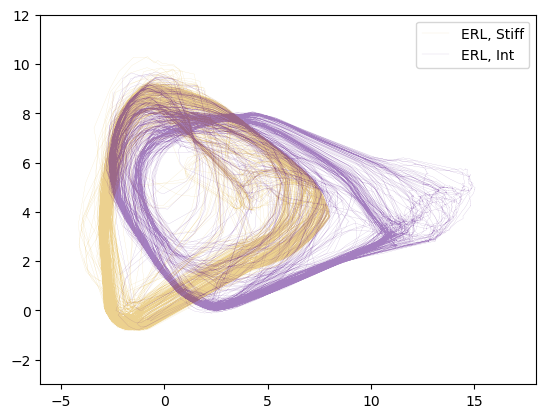

In [26]:
fig = plt.figure()
plt.plot(embedding_all_prot[4*trk_len:5*trk_len,0], embedding_all_prot[4*trk_len:5*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Stiff', color='goldenrod')
plt.plot(embedding_all_prot[5*trk_len:6*trk_len,0], embedding_all_prot[5*trk_len:6*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Int', color='indigo')
plt.xlim(-6, 18)
plt.ylim(-3, 12)
plt.legend()

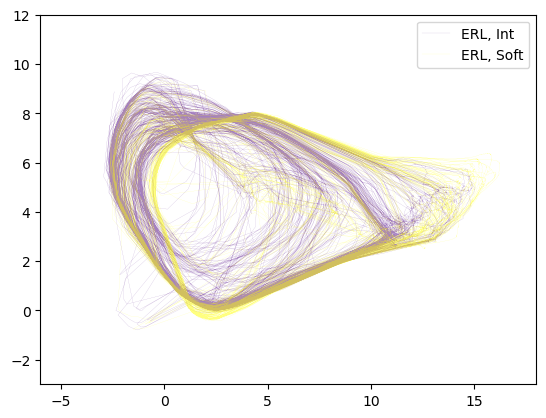

In [27]:
fig = plt.figure()
plt.plot(embedding_all_prot[5*trk_len:6*trk_len,0], embedding_all_prot[5*trk_len:6*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Int', color='indigo')
plt.plot(embedding_all_prot[2*trk_len:3*trk_len,0], embedding_all_prot[2*trk_len:3*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Soft', color='yellow')
plt.xlim(-6, 18)
plt.ylim(-3, 12)
plt.legend()

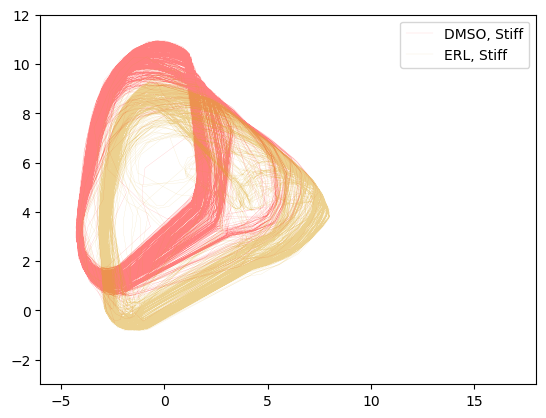

In [28]:
fig = plt.figure()
plt.plot(embedding_all_prot[0*trk_len:1*trk_len,0], embedding_all_prot[0*trk_len:1*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Stiff', color='red')
plt.plot(embedding_all_prot[4*trk_len:5*trk_len,0], embedding_all_prot[4*trk_len:5*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Stiff', color='goldenrod')
plt.xlim(-6, 18)
plt.ylim(-3, 12)
plt.legend()

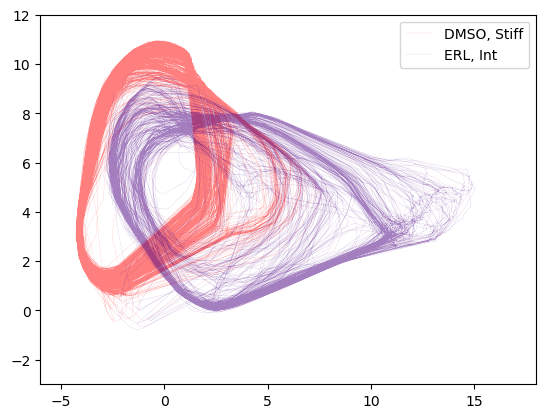

In [29]:
fig = plt.figure()
plt.plot(embedding_all_prot[0*trk_len:1*trk_len,0], embedding_all_prot[0*trk_len:1*trk_len,1], lw=0.1, alpha=0.5, label='DMSO, Stiff', color='red')
plt.plot(embedding_all_prot[5*trk_len:6*trk_len,0], embedding_all_prot[5*trk_len:6*trk_len,1], lw=0.1, alpha=0.5, label='ERL, Int', color='indigo')
plt.xlim(-6, 18)
plt.ylim(-3, 12)
plt.legend()

In [30]:
all_prot_tmp.shape

(59976, 900)

In [31]:
all_prot_tmp[:10,:10]

array([[0.22641509, 0.22641509, 0.24528302, 0.24528302, 0.22641509,
        0.20754717, 0.20754717, 0.20754717, 0.20754717, 0.20754717],
       [0.20754717, 0.20754717, 0.20754717, 0.20754717, 0.22641509,
        0.22641509, 0.22641509, 0.22641509, 0.22641509, 0.22641509],
       [0.20754717, 0.20754717, 0.20754717, 0.22641509, 0.22641509,
        0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302],
       [0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302,
        0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302],
       [0.24528302, 0.22641509, 0.22641509, 0.22641509, 0.22641509,
        0.22641509, 0.22641509, 0.22641509, 0.22641509, 0.22641509],
       [0.22641509, 0.22641509, 0.22641509, 0.22641509, 0.24528302,
        0.24528302, 0.24528302, 0.24528302, 0.24528302, 0.24528302],
       [0.24528302, 0.24528302, 0.26415094, 0.28301887, 0.32075472,
        0.32075472, 0.32075472, 0.32075472, 0.32075472, 0.32075472],
       [0.32075472, 0.32075472, 0.3207547

In [32]:
np.savetxt(Path(SAVE_DIR,'all_prot_tmp.csv'), all_prot_tmp, delimiter=",")